In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [18]:
d1 = find_file("240510_TS_C10_W3S2_run1.DSC", exp_type="francklab_esr/romana") # cooling 1 --initial sample
d2 = find_file("240510_TS_C10_W3S2_run2.DSC", exp_type="francklab_esr/romana") # heating 2 subsequently --after cooling and heating

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 3$ in Dodecane for cooling1')

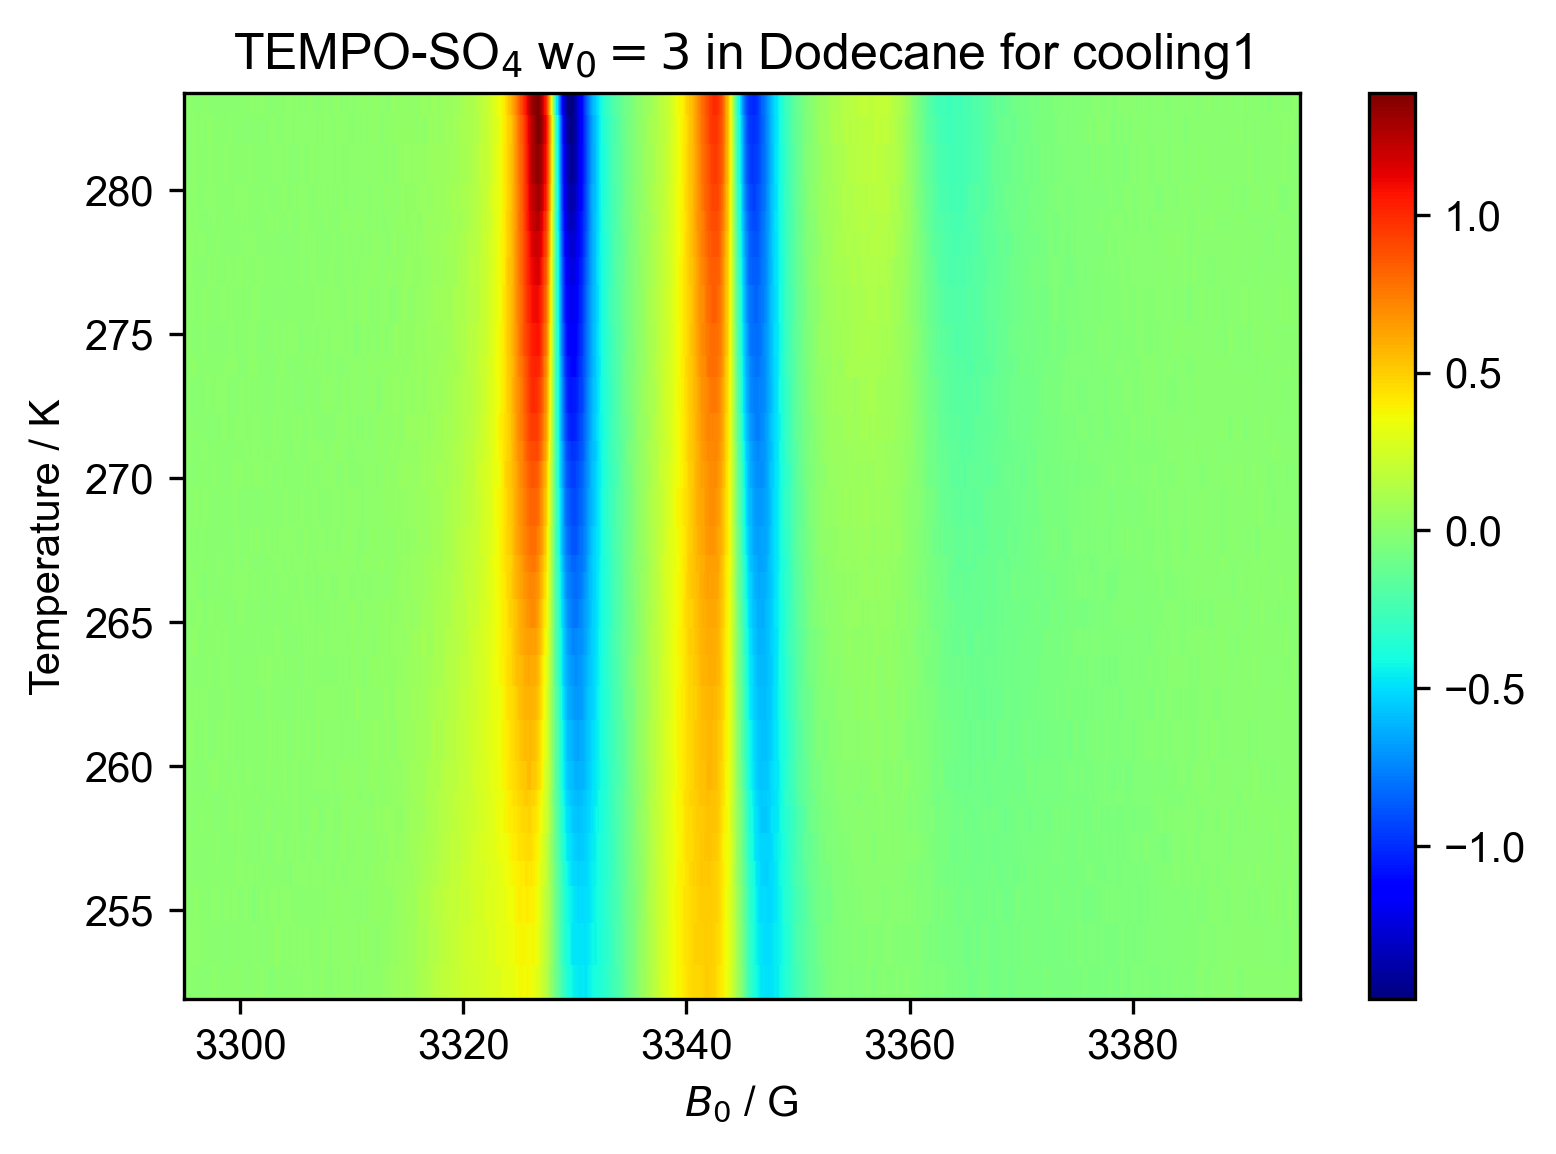

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 3$ in Dodecane for cooling1")

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 3$ in Dodecane for heating1')

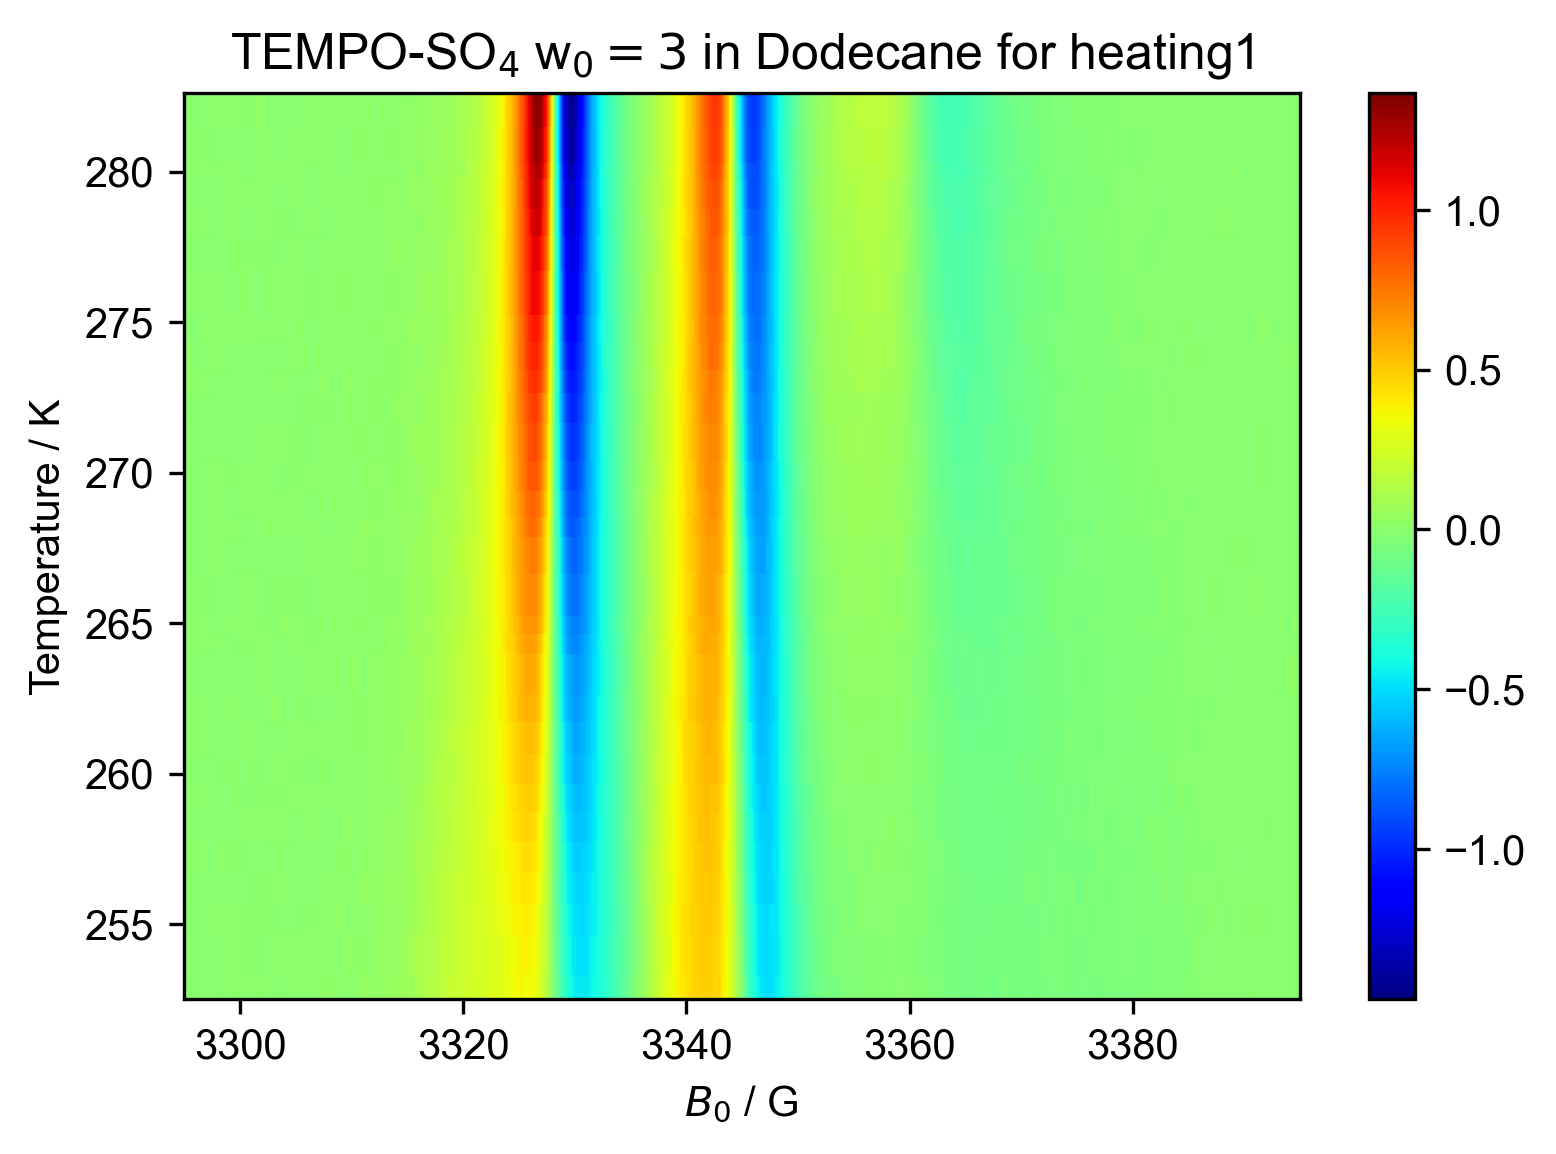

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 3$ in Dodecane for heating1")

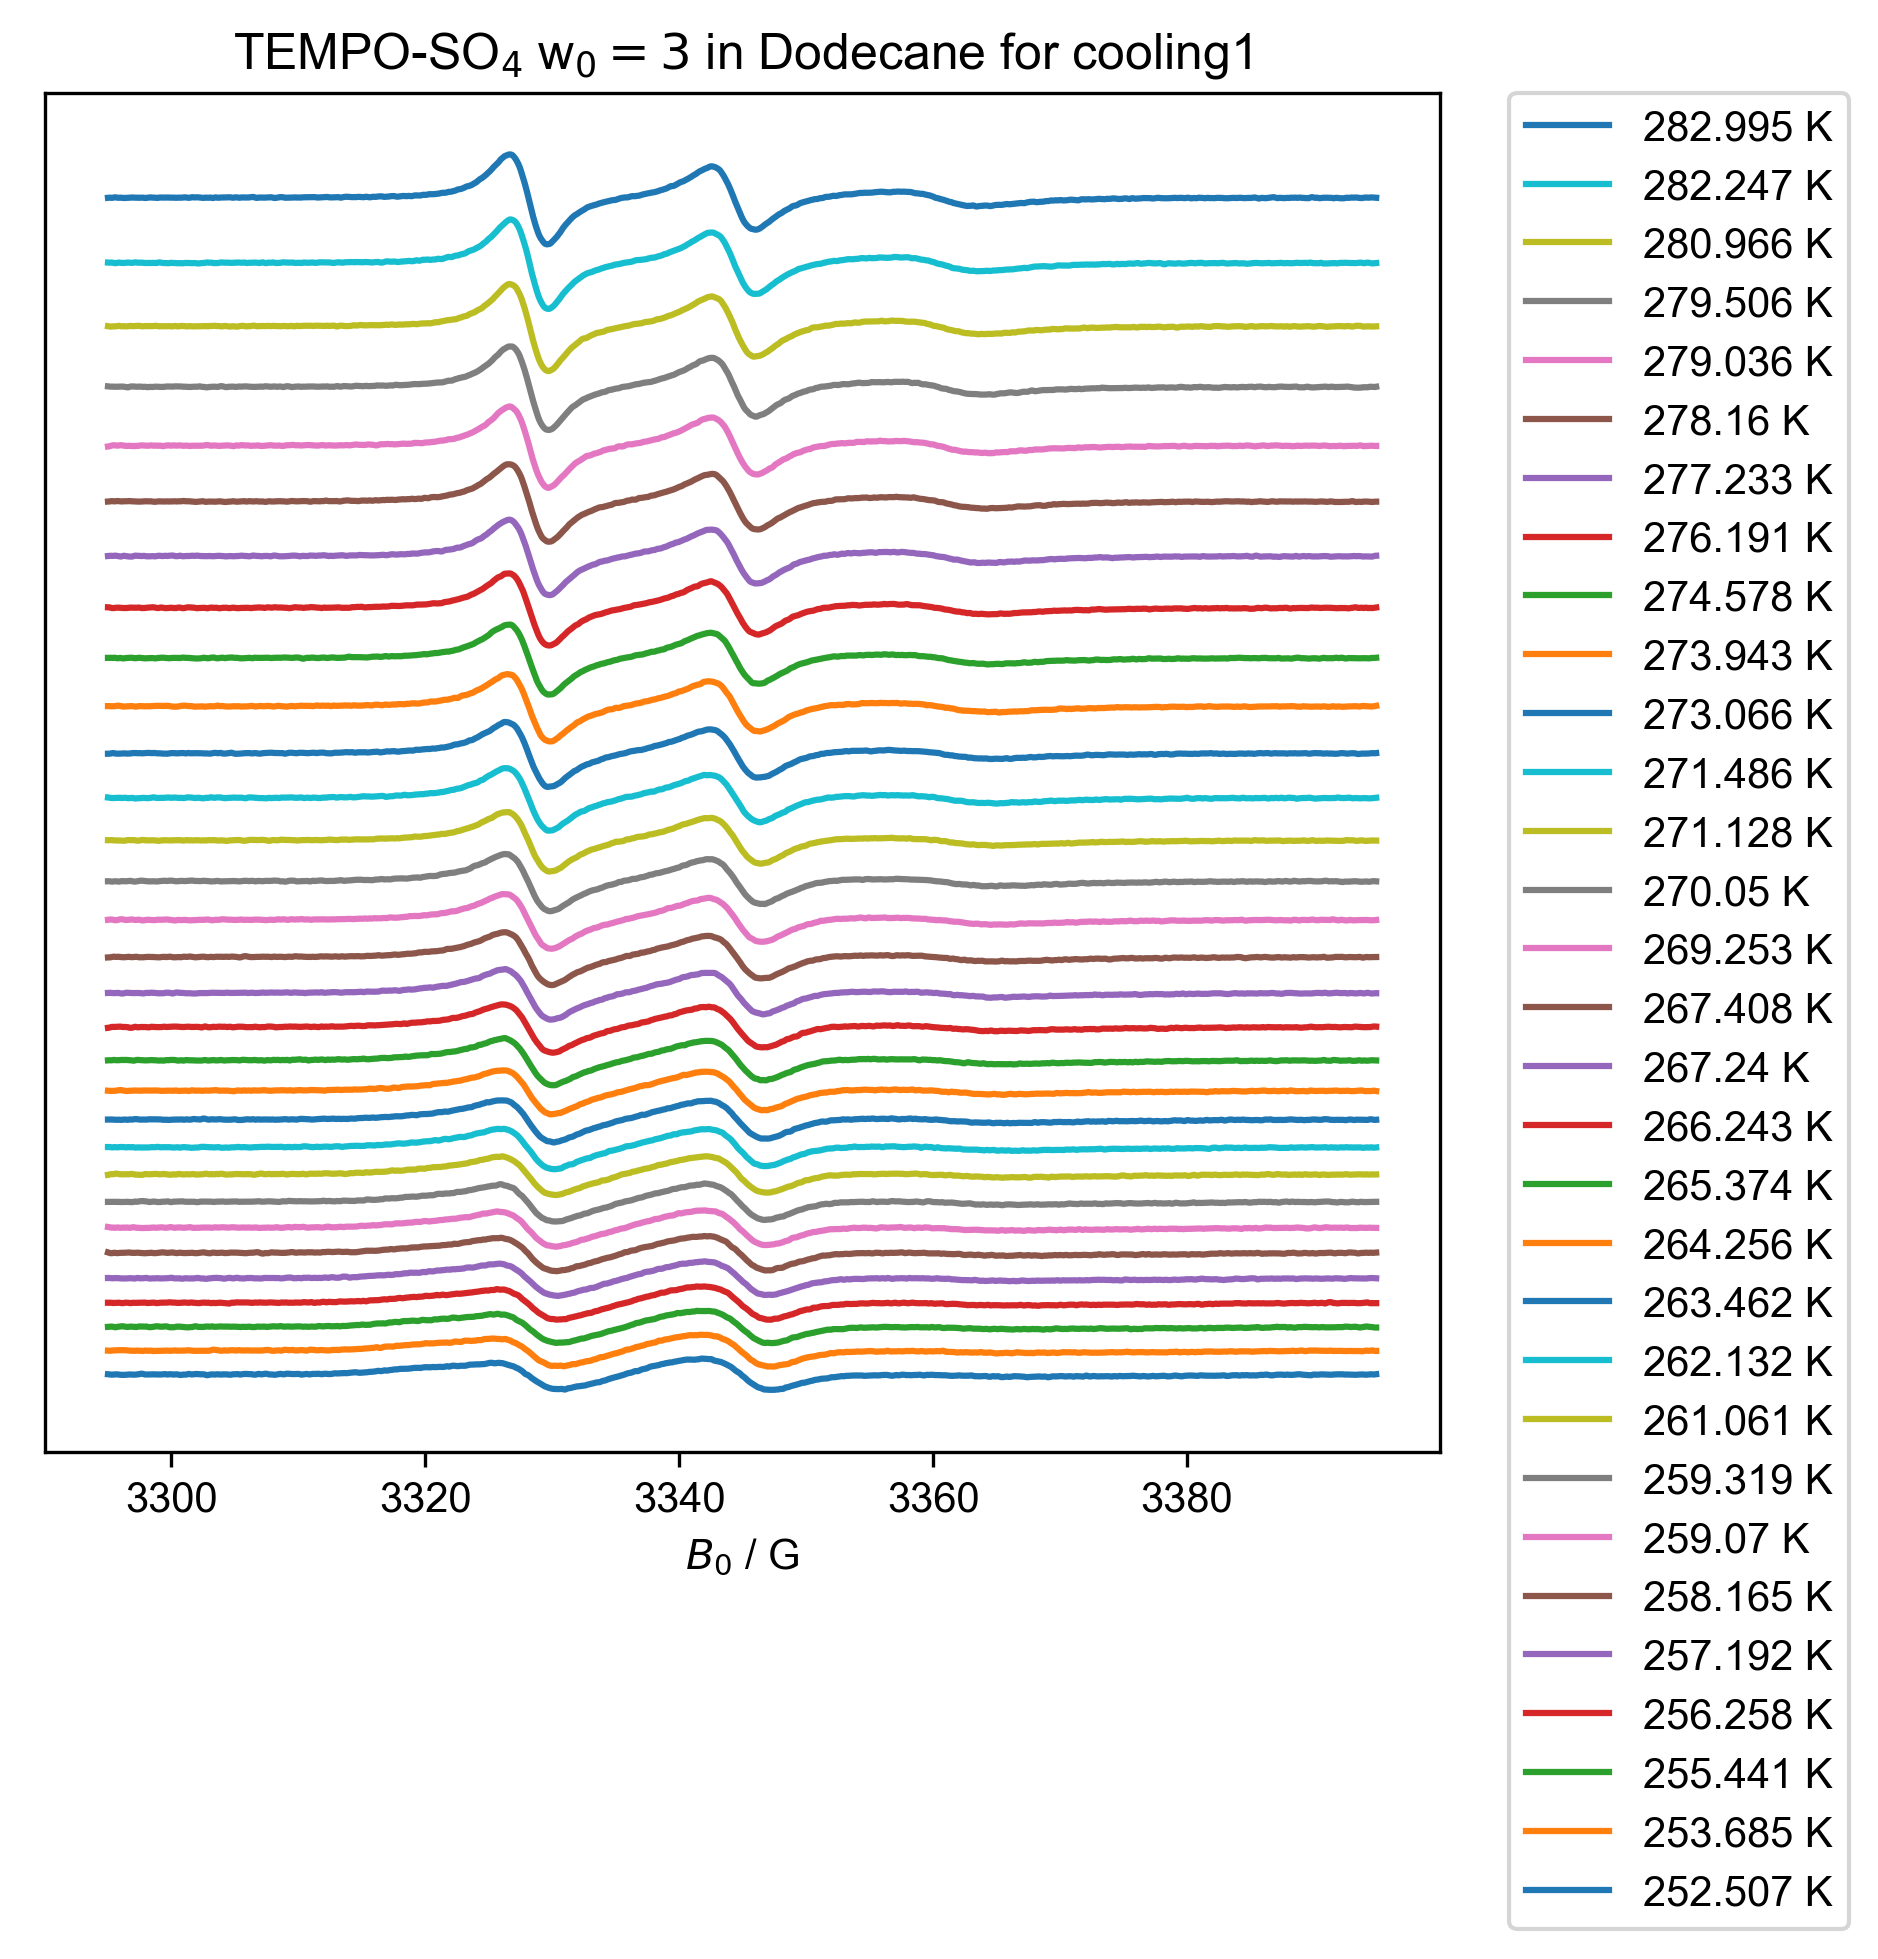

In [9]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 3$ in Dodecane for cooling1", (200, 300))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

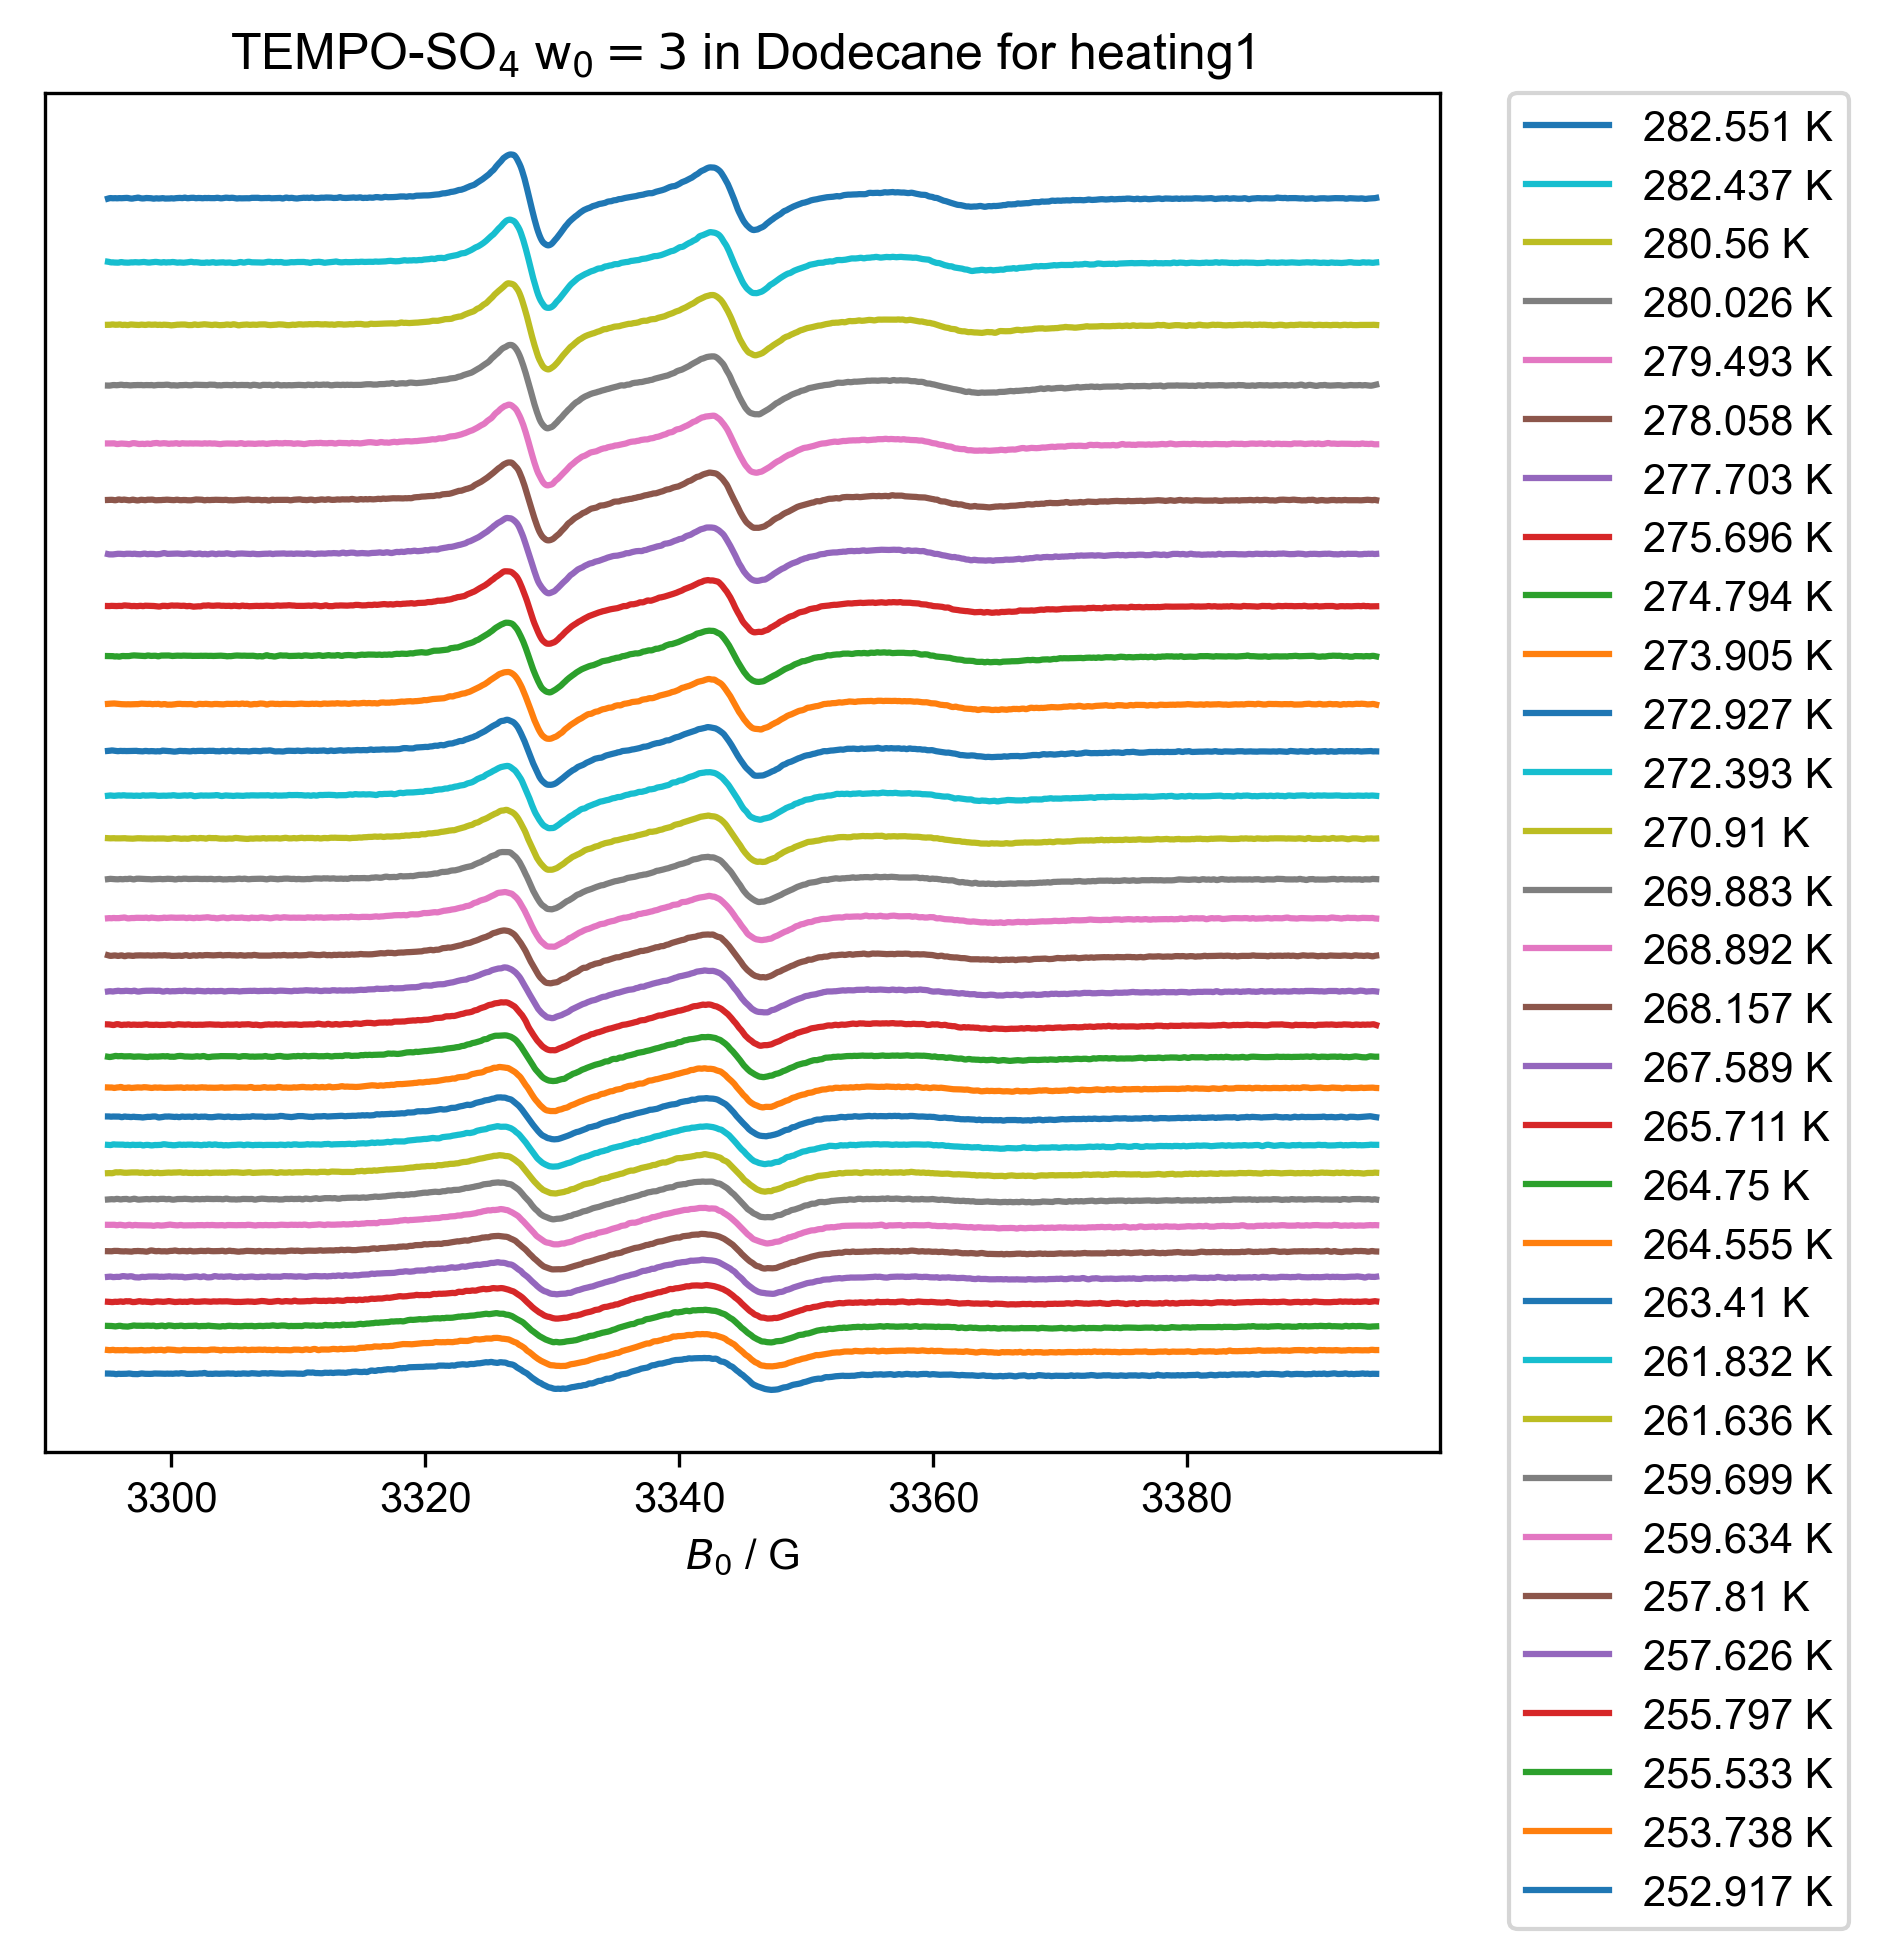

In [10]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0=3$ in Dodecane for heating1", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

[252.507 253.685 255.441 256.258 257.192 258.165 259.07  259.319 261.061
 262.132 263.462 264.256 265.374 266.243 267.24  267.408 269.253 270.05
 271.128 271.486 273.066 273.943 274.578 276.191 277.233 278.16  279.036
 279.506 280.966 282.247 282.995]
[252.917 253.738 255.533 255.797 257.626 257.81  259.634 259.699 261.636
 261.832 263.41  264.555 264.75  265.711 267.589 268.157 268.892 269.883
 270.91  272.393 272.927 273.905 274.794 275.696 277.703 278.058 279.493
 280.026 280.56  282.437 282.551]


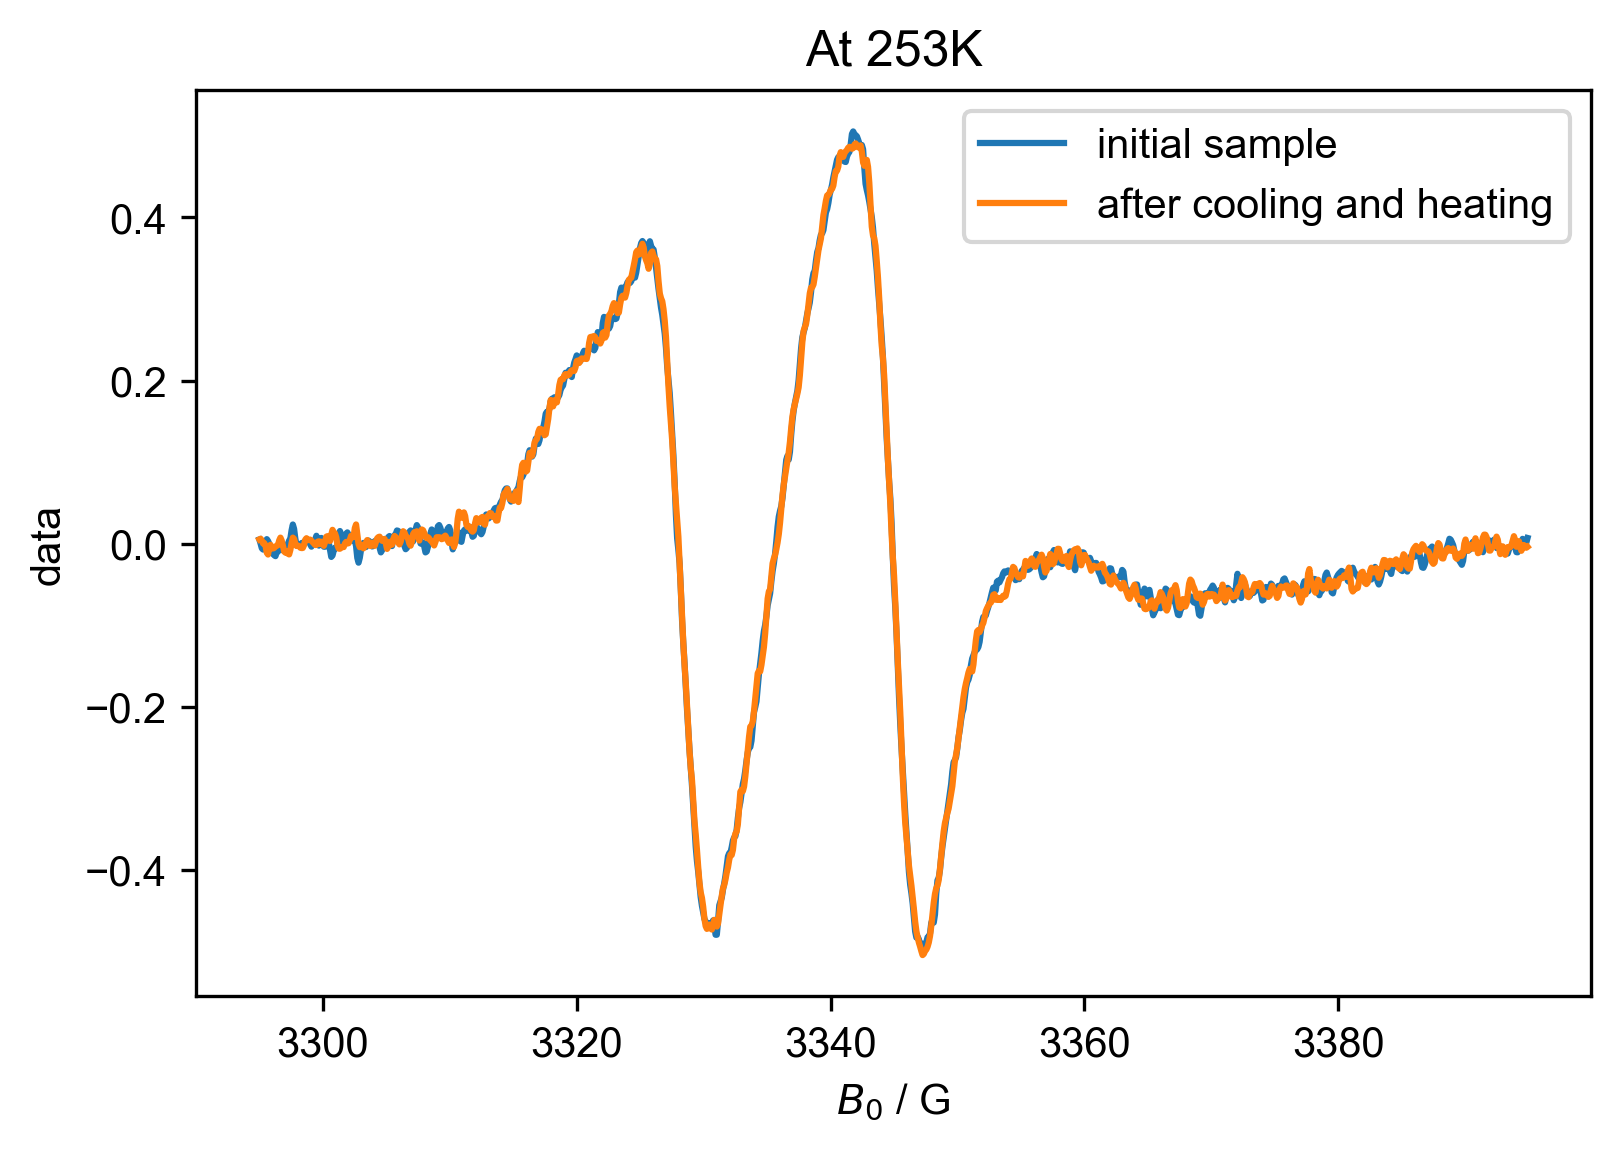

In [11]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":253], label="initial sample")
plot(d2["Temperature":253], label="after cooling and heating")
title("At 253K")
legend()

[252.507 253.685 255.441 256.258 257.192 258.165 259.07  259.319 261.061
 262.132 263.462 264.256 265.374 266.243 267.24  267.408 269.253 270.05
 271.128 271.486 273.066 273.943 274.578 276.191 277.233 278.16  279.036
 279.506 280.966 282.247 282.995]
[252.917 253.738 255.533 255.797 257.626 257.81  259.634 259.699 261.636
 261.832 263.41  264.555 264.75  265.711 267.589 268.157 268.892 269.883
 270.91  272.393 272.927 273.905 274.794 275.696 277.703 278.058 279.493
 280.026 280.56  282.437 282.551]


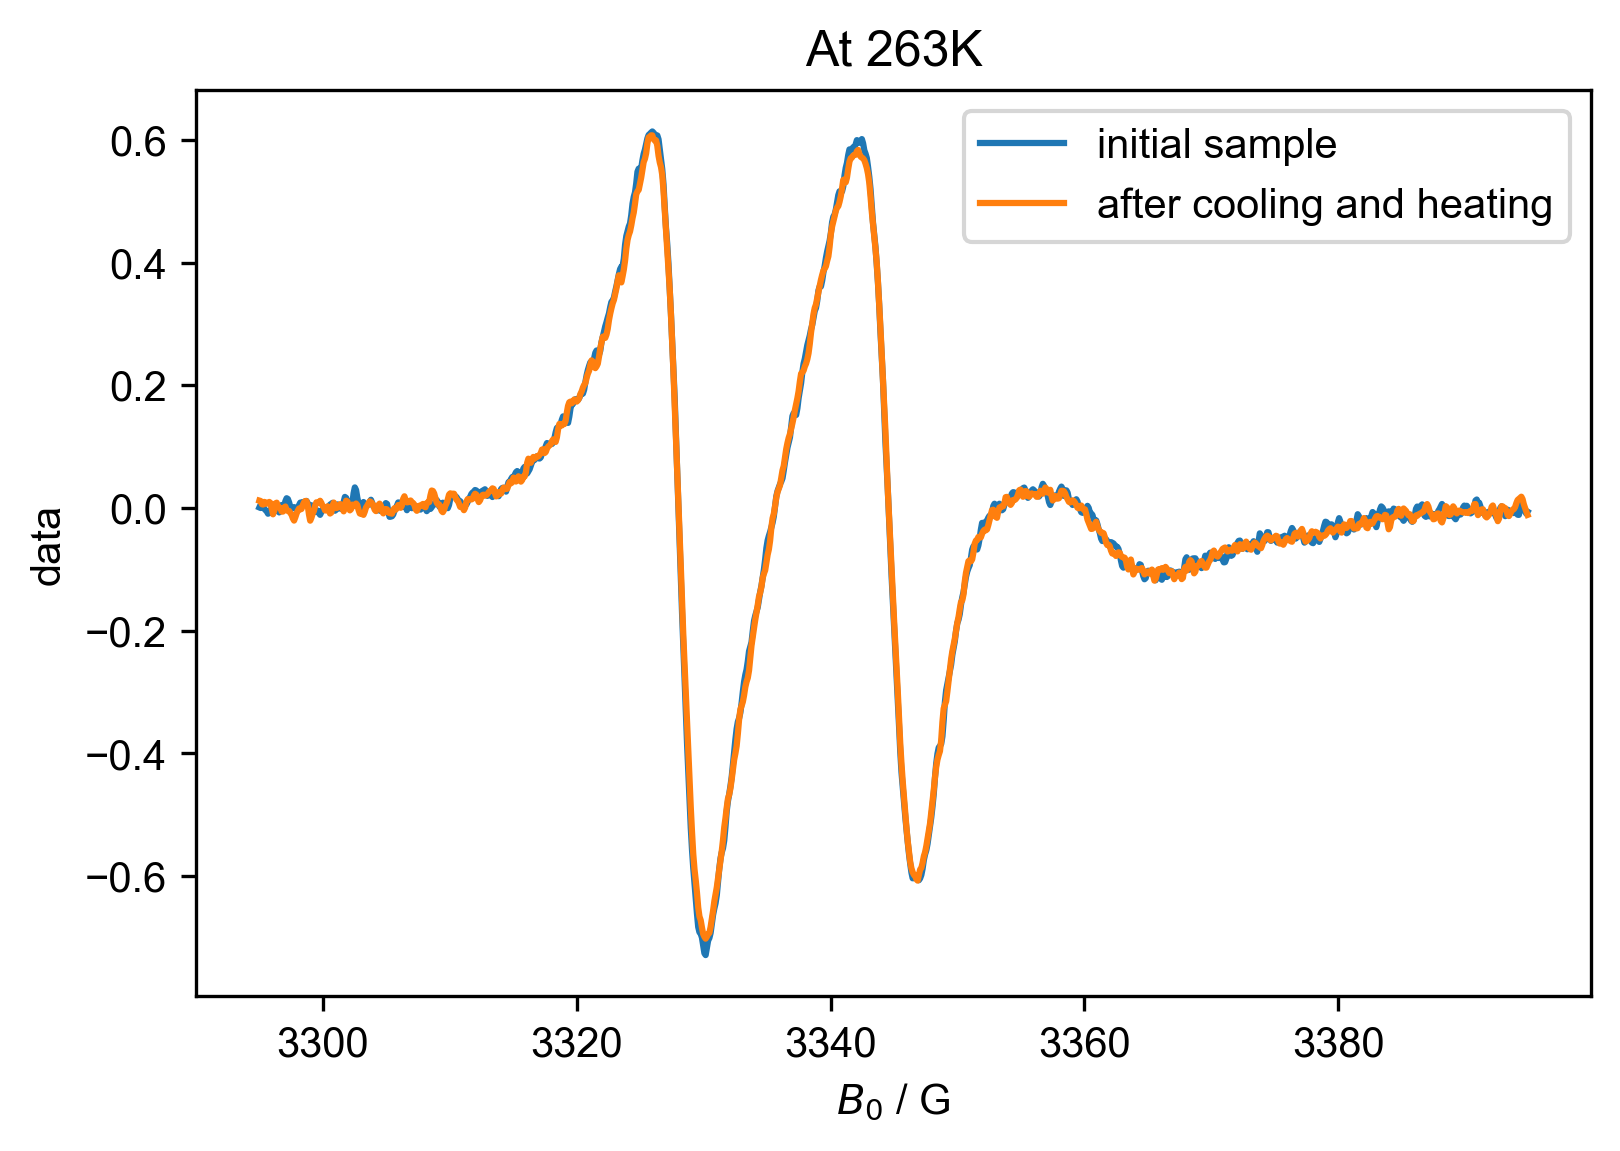

In [12]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":263], label="initial sample")
plot(d2["Temperature":263], label="after cooling and heating")
title("At 263K")
legend()

[252.507 253.685 255.441 256.258 257.192 258.165 259.07  259.319 261.061
 262.132 263.462 264.256 265.374 266.243 267.24  267.408 269.253 270.05
 271.128 271.486 273.066 273.943 274.578 276.191 277.233 278.16  279.036
 279.506 280.966 282.247 282.995]
[252.917 253.738 255.533 255.797 257.626 257.81  259.634 259.699 261.636
 261.832 263.41  264.555 264.75  265.711 267.589 268.157 268.892 269.883
 270.91  272.393 272.927 273.905 274.794 275.696 277.703 278.058 279.493
 280.026 280.56  282.437 282.551]


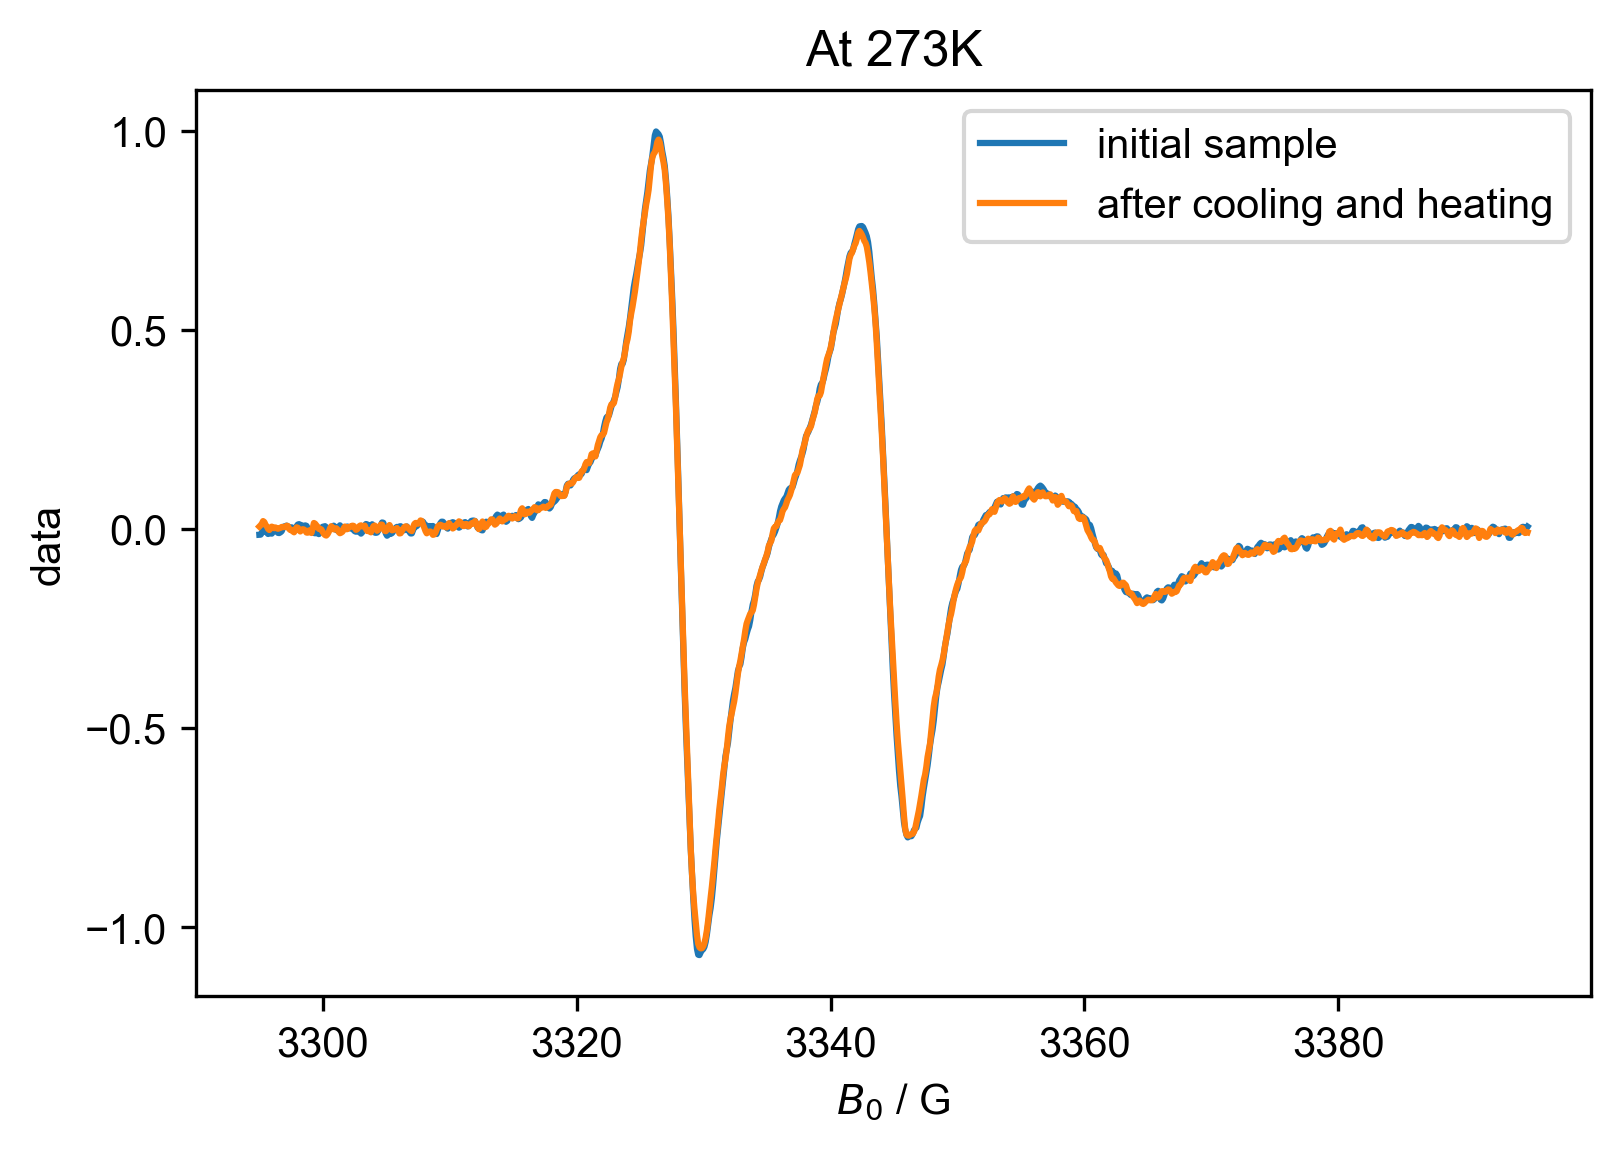

In [13]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":273], label="initial sample")
plot(d2["Temperature":273], label="after cooling and heating")
title("At 273K")
legend()

[252.507 253.685 255.441 256.258 257.192 258.165 259.07  259.319 261.061
 262.132 263.462 264.256 265.374 266.243 267.24  267.408 269.253 270.05
 271.128 271.486 273.066 273.943 274.578 276.191 277.233 278.16  279.036
 279.506 280.966 282.247 282.995]
[252.917 253.738 255.533 255.797 257.626 257.81  259.634 259.699 261.636
 261.832 263.41  264.555 264.75  265.711 267.589 268.157 268.892 269.883
 270.91  272.393 272.927 273.905 274.794 275.696 277.703 278.058 279.493
 280.026 280.56  282.437 282.551]


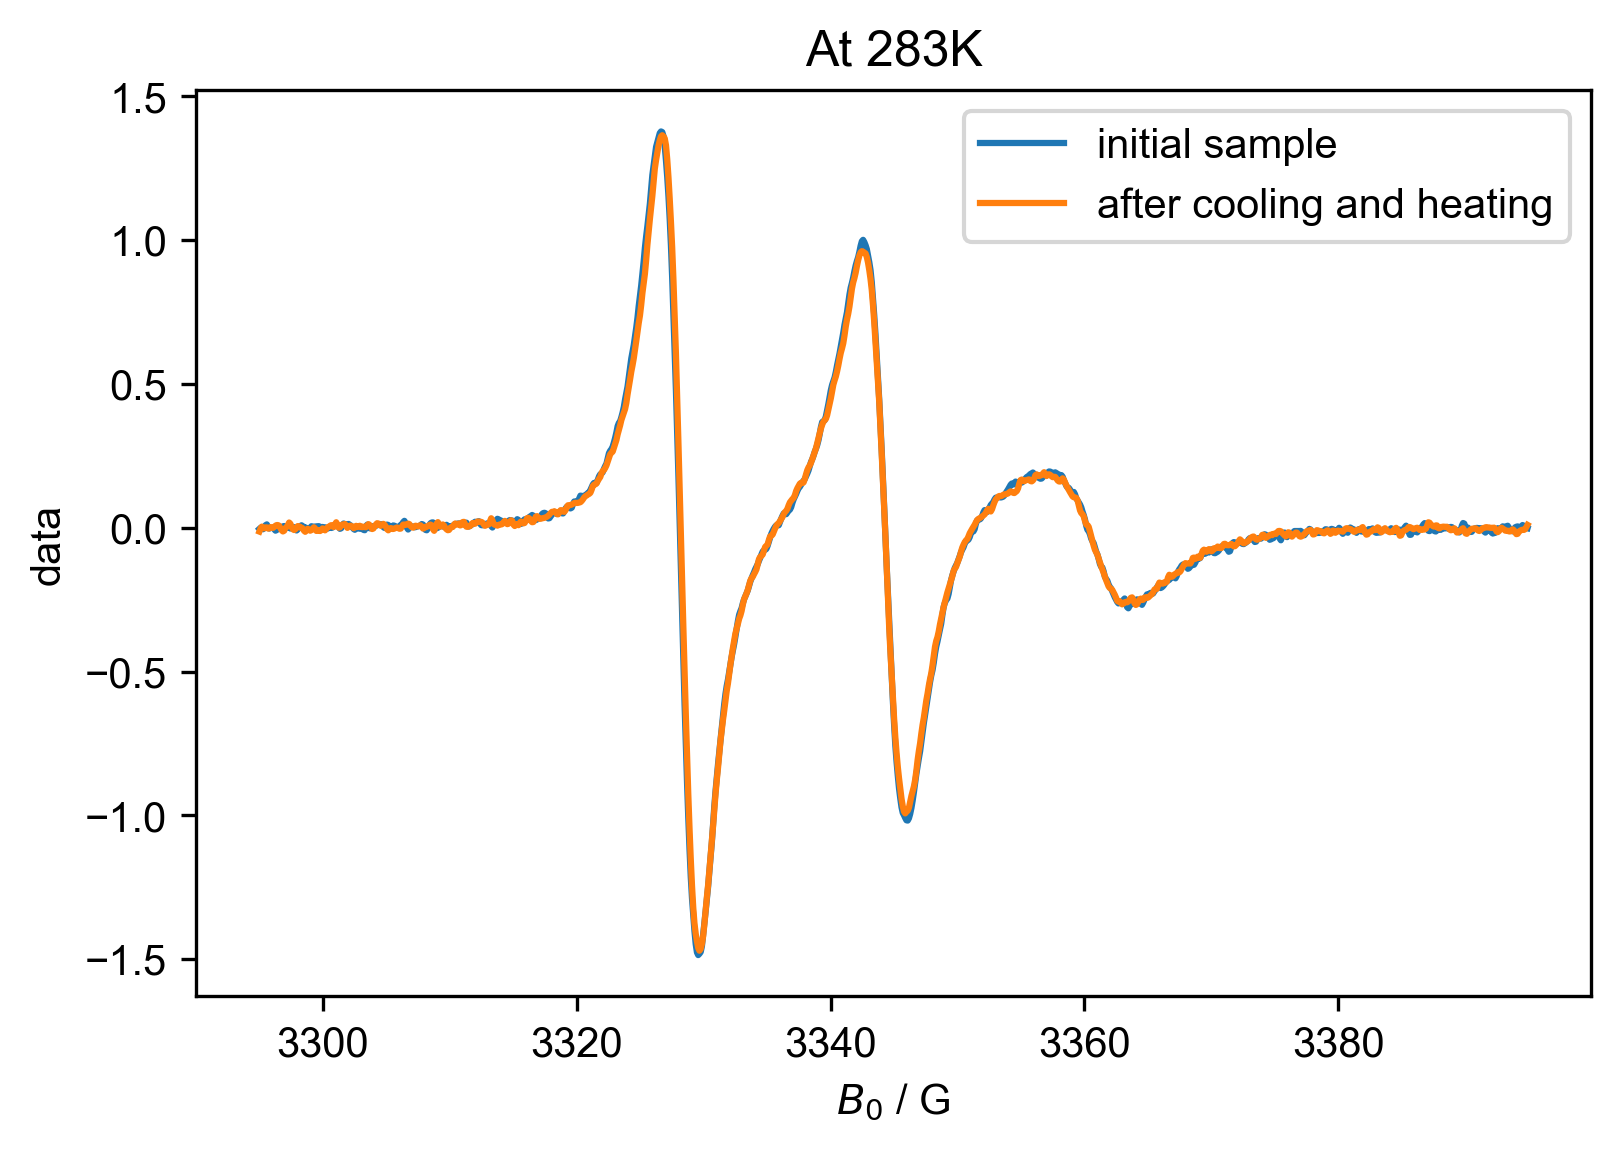

In [14]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":283], label="initial sample")
plot(d2["Temperature":283], label="after cooling and heating")
title("At 283K")
legend()

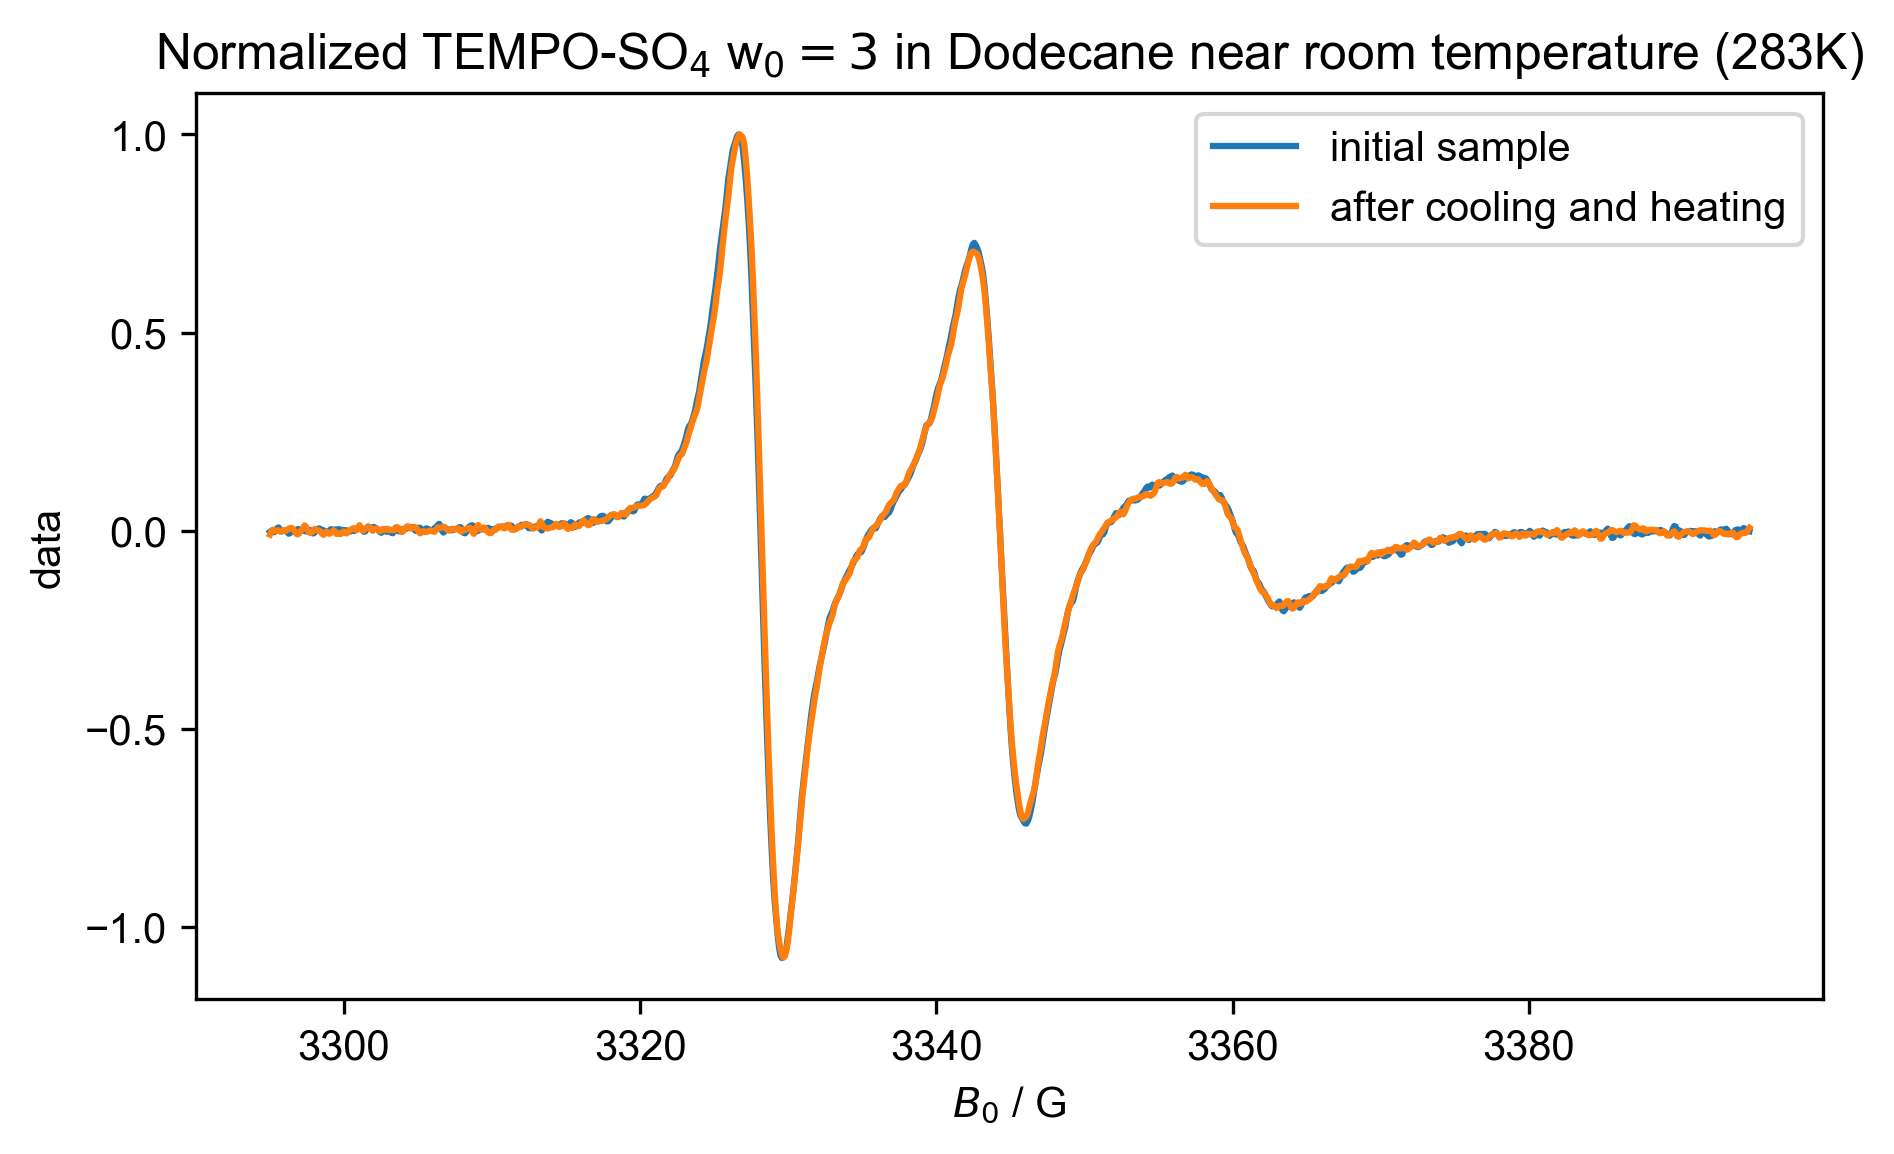

In [15]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "initial sample")
plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label= "after cooling and heating")
title("Normalized TEMPO-SO$_4$ w$_0= 3$ in Dodecane near room temperature (283K)")
legend()